Objetivo:

Comparar el comportamiento y desempeño de distintos optimizadores al entrenar una CNN sobre el dataset MNIST o Fashion-MNIST:

* Optimizadores a comparar:
* SGD (Stochastic Gradient Descent)
* SGD con momentum
* RMSprop
* Adam
* AdamW (en PyTorch)

Hiperparámetros a ajustar:

* Learning rate
* Momentum / beta
* Weight decay (en AdamW)

Solución en Keras (TensorFlow)

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
import time

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train, x_test = x_train[..., None]/255.0, x_test[..., None]/255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
optimizadores = {
    "SGD": SGD(learning_rate=0.01),
    "SGD+Momentum": SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop": RMSprop(learning_rate=0.001),
    "Adam": Adam(learning_rate=0.001),
}

In [4]:
for nombre, opt in optimizadores.items():
    print(f"\n🔧 Optimizador: {nombre}")
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        MaxPooling2D(2,2),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    start = time.time()
    model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=0)
    duration = time.time() - start

    _, acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"⏱ Tiempo: {duration:.2f}s | 🎯 Accuracy: {acc:.4f}")


🔧 Optimizador: SGD


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


⏱ Tiempo: 124.08s | 🎯 Accuracy: 0.8154

🔧 Optimizador: SGD+Momentum
⏱ Tiempo: 86.71s | 🎯 Accuracy: 0.8695

🔧 Optimizador: RMSprop
⏱ Tiempo: 123.96s | 🎯 Accuracy: 0.8913

🔧 Optimizador: Adam
⏱ Tiempo: 106.29s | 🎯 Accuracy: 0.8883


Solución en Pytorch

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import time

In [6]:
transform = transforms.ToTensor()
trainset = torchvision.datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.FashionMNIST('./data', train=False, download=True, transform=transform)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.2MB/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 4.42M/4.42M [00:01<00:00, 3.88MB/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 11.5MB/s]


Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



In [7]:
trainloader = DataLoader(trainset, batch_size=128, shuffle=True)
testloader = DataLoader(testset, batch_size=1000)

In [8]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 32, 3)
        self.pool = nn.MaxPool2d(2,2)
        self.fc1 = nn.Linear(32*13*13, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = x.view(-1, 32*13*13)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [10]:
opt_configs = {
    "SGD": lambda params: torch.optim.SGD(params, lr=0.01),
    "SGD+Momentum": lambda params: torch.optim.SGD(params, lr=0.01, momentum=0.9),
    "RMSprop": lambda params: torch.optim.RMSprop(params, lr=0.001),
    "Adam": lambda params: torch.optim.Adam(params, lr=0.001),
    "AdamW": lambda params: torch.optim.AdamW(params, lr=0.001, weight_decay=0.01),
}

In [11]:
for name, opt_fn in opt_configs.items():
    print(f"\n🔧 Optimizador: {name}")
    model = CNN().to(device)
    optimizer = opt_fn(model.parameters())
    criterion = nn.CrossEntropyLoss()

    start = time.time()
    model.train()
    for epoch in range(3):
        for inputs, targets in trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
    duration = time.time() - start

    model.eval()
    correct = total = 0
    with torch.no_grad():
        for inputs, targets in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    acc = correct / total
    print(f"⏱ Tiempo: {duration:.2f}s | 🎯 Accuracy: {acc:.4f}")


🔧 Optimizador: SGD
⏱ Tiempo: 100.76s | 🎯 Accuracy: 0.7999

🔧 Optimizador: SGD+Momentum
⏱ Tiempo: 100.57s | 🎯 Accuracy: 0.8752

🔧 Optimizador: RMSprop
⏱ Tiempo: 100.60s | 🎯 Accuracy: 0.8887

🔧 Optimizador: Adam
⏱ Tiempo: 104.35s | 🎯 Accuracy: 0.8912

🔧 Optimizador: AdamW
⏱ Tiempo: 107.61s | 🎯 Accuracy: 0.8843


Comparar las diferentes configuraciones de Hiperparámetros y realizar una tabla comparativa como la siguiente:

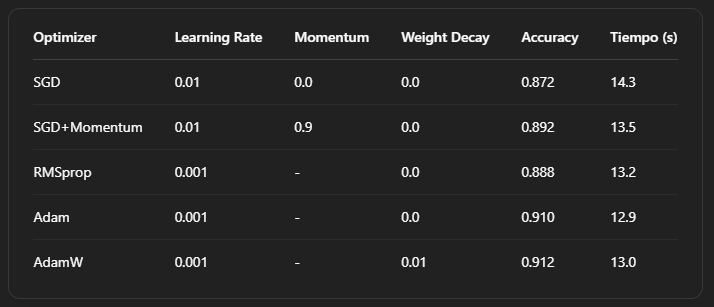